# SUMO mobility

**Upstream has no SUMO support.** It has leftovers from the authors' private setup (`PositionChecker`, `EnableTX`, polygons of a city), but no way to load traffic. Its `HIGHWAY` puts vehicles on 6 lanes with constant speed, and they drive past the end of the road.

It is now mounted the way your groupcast simulator does it, with a TraCI client and a pool of nodes. Two modes:

| Mode | Option | Use it for |
|---|---|---|
| Live | `--sumoCfg=<file>` | ns-3 starts SUMO and exchanges positions every `--sumoSync` seconds. Later, it allows feedback into traffic |
| Replay | `--mobilityTrace=<csv>` | Same mobility in every run, no SUMO process, no port |

```bash
./waf --run "HIGHWAY --Vehicles=80 --simTime=10 --Periodic --mcs=13 --sumoCfg=scenarios/sumo/highway_2km/highway.sumocfg --sumoWarmup=90 --PosLog=true"
```

**Measured on ns-3.22.** The figures here come from `develop`. The ns-3.42 port reproduces them within the confidence intervals, see [notebook 06](06_ns3_migration.ipynb). Commands in this notebook use the `ns-3.22` file names where they differ, see `COMMANDS.txt` for this branch.

## How it fits together

```
HIGHWAY                 SumoMobilityHelper               TraciClient               sumo
   |  InstallParked (nodes) |                                |                       |
   |----------------------->| ConstantVelocity, parked       |                       |
   |  InstallUeDevice       |                                |                       |
   |  Start (enter, leave)  |  SumoSetup                     |   system("sumo ...")  |
   |----------------------->|------------------------------->|---------------------->|
   |                        |                                |   StartTime warm-up   |
   |    every sync interval |                                |<--- departed/arrived -|
   |                        |<-- VehicleDeparted (id) -------|                       |
   |<-- enter: EnableTX on -|    takes a free node           |--- position, speed,   |
   |                        |                                |    angle per vehicle  |
   |<-- leave: EnableTX off |<-- VehicleArrived (node, id) --|                       |
   |                        |    parks it 0.2 s later        |                       |
```

**Why a pool.** ns-3.22 cannot add a device once the channel exists, and `NrV2XPropagationLossModel::InitChannelMatrix` sizes its matrix once. So `--Vehicles` nodes exist from the start, parked 100 km away. It is the size of the pool, not the number of cars. A run prints `Peak active vehicles N, vehicles without a node M`. If M is above 0, raise `--Vehicles`.

**Parked nodes do nothing.** `UdpClient::Send` polls `EnableTX`, which is off until a vehicle claims the node. They are out of radio range and outside the logging window.

## Differences from the groupcast version

The client is a copy of `ns-3-dev/src/traci`. The groupcast folder was only read.

| Change | Why it was needed here |
|---|---|
| Velocity is sent to the node, computed from `vehicle.getSpeed` and `vehicle.getAngle` | **Important.** `ConstantPositionMobilityModel` reports speed 0. MoReV2X picks its BLER curves from `GetRelativeSpeed`, split at 200 km/h, which opposite lanes exceed |
| A vehicle with no free node is skipped | Upstream code stores a null node and crashes in `UpdatePositions` |
| Nodes are recycled when vehicles leave | Long runs need only the peak number of vehicles, not the total |
| A departed node stays in place for 0.2 s (`parkDelay`) | A packet generated just before departure would otherwise be sent from the parking lot |
| Connection is polled | A fixed 1 s sleep races with SUMO startup |
| First sync reads `vehicle.getIDList` | The departed list only covers one step, so `--sumoWarmup` would lose every vehicle |
| Web visualizer removed | Not needed, and it would pull in another module |

The same velocity point applies to your groupcast mobility, since it installs `ConstantPositionMobilityModel` too: under SUMO, ns-3 sees those nodes as stationary.

Logging windows also had to change. The CBR and reception logs only covered `x` in a fixed range for the 5 km highway. `HIGHWAY` widens them in SUMO mode through `CbrMinX/MaxX` and `MetricsMinX/MaxX`.

## The example scenario

`scenarios/sumo/highway_2km/`: two directions with 3 lanes each, cars at 130 km/h and trucks at 90 km/h. Flows fill the road in about 55 s, so `--sumoWarmup=90` starts ns-3 on steady traffic.

The `<end>` time in the `.sumocfg` must exceed `--simTime + --sumoWarmup + 1`, or SUMO stops first and ns-3 aborts.

To use another map, write a `.sumocfg` with `step-length` equal to `--sumoSync`, and pass its path. The propagation model is the 3GPP highway one, whatever the map: urban geometry has no effect on the channel.

In [1]:
import os, subprocess, sys
sys.path.insert(0, os.path.abspath("../../tools"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
mr.apply_chart_style()
os.chdir(mr.ROOT)

In [2]:
sumo_cfg = os.path.join(mr.ROOT, "scenarios/sumo/highway_2km/highway.sumocfg")
run = mr.simulate("sumo", "--Vehicles=90", "--simTime=20", "--mcs=13", "--seed=1", "--Periodic", "--PosLog=true",
                  "--sumoCfg=" + sumo_cfg, "--sumoWarmup=90")
print(open(os.path.join(os.path.dirname(os.path.dirname(run.folder)), "stdout.log")).read().splitlines()[-1])
positions = run.positions[run.positions.y > -5e4]
print(positions.node.nunique(), "nodes used, of", run.positions.node.nunique())

Peak active vehicles 69, vehicles without a node 0
87 nodes used, of 90


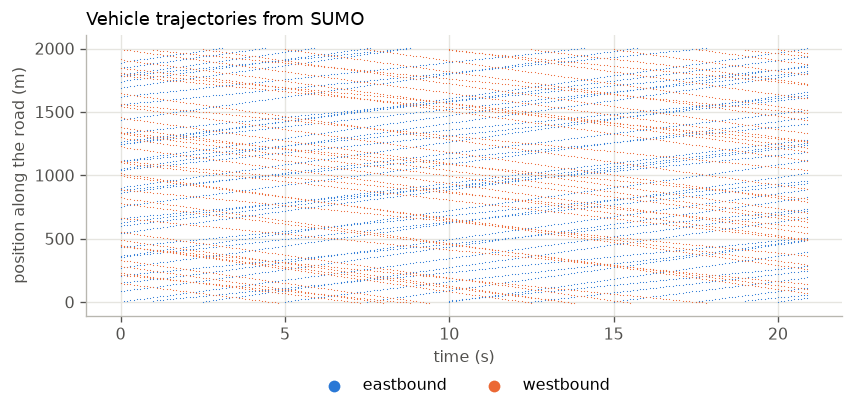

In [3]:
fig, ax = plt.subplots()
east = positions[positions.y < 0]   # SUMO drives on the right
west = positions[positions.y >= 0]
ax.scatter(east.time, east.x, s=0.5, color=mr.SERIES_COLORS[0], label="eastbound", linewidths=0)
ax.scatter(west.time, west.x, s=0.5, color=mr.SERIES_COLORS[1], label="westbound", linewidths=0)
ax.set_xlabel("time (s)")
ax.set_ylabel("position along the road (m)")
ax.legend(markerscale=10, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.set_title("Vehicle trajectories from SUMO")
plt.tight_layout()

Each line is a vehicle. Slopes are road speed, and new lines appear as vehicles enter.

{'PDR near': 0.956, 'collision share': 0.152, 'CBR': 0.224, 'latency p95 [ms]': 90.9, 'selections': 1347.0, 'transmissions': 24140.0}


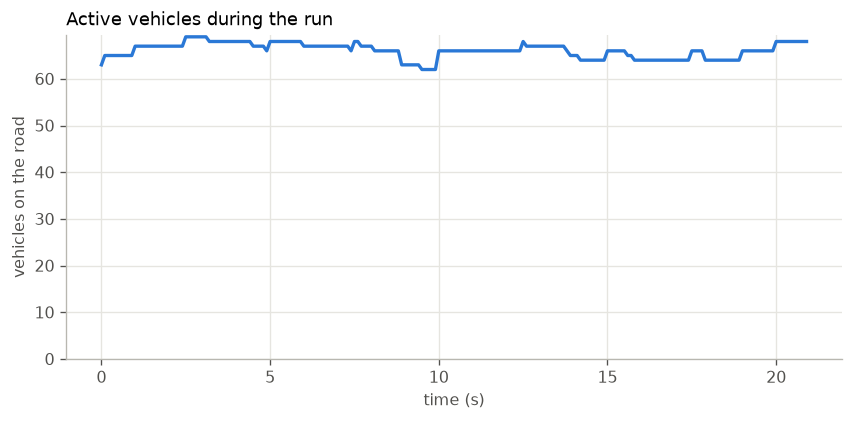

In [4]:
fig, ax = plt.subplots()
active = positions.groupby("time").node.nunique()
ax.plot(active.index, active.values, color=mr.SERIES_COLORS[0])
ax.set_xlabel("time (s)")
ax.set_ylabel("vehicles on the road")
ax.set_ylim(bottom=0)
ax.set_title("Active vehicles during the run")
plt.tight_layout()
print(mr.summary(run).round(3).to_dict())

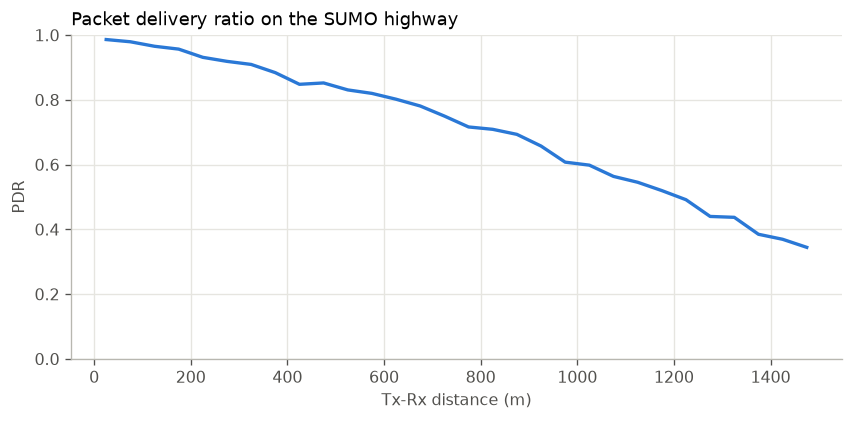

In [5]:
fig, ax = plt.subplots()
pdr = mr.pdr_by_distance(run.rx, bin_m=50, max_m=1500)
ax.plot(pdr.index, pdr.values, color=mr.SERIES_COLORS[0])
ax.set_xlabel("Tx-Rx distance (m)")
ax.set_ylabel("PDR")
ax.set_ylim(0, 1)
ax.set_title("Packet delivery ratio on the SUMO highway")
plt.tight_layout()

**Reading.** The 2 km road holds about 66 vehicles (33 per km) in steady state, CBR 0.22, with near PDR 0.96. 87 of the 90 nodes were used over 20 s, and the peak was 69, so recycling works and nothing was rejected.

## Replay

Records SUMO once, then runs without it. `tools/fcd2trace.py` turns `fcd-output` into `time,node_id,x,y,speed`, the format of your groupcast traces. The `node_id` is the pool index.

```bash
sumo -c scenarios/sumo/highway_2km/highway.sumocfg --end 120 --fcd-output results/fcd.xml
tools/fcd2trace.py results/fcd.xml results/trace.csv --begin 90
./waf --run "HIGHWAY --Vehicles=80 --simTime=10 --Periodic --mcs=13 --mobilityTrace=results/trace.csv"
```

The speed column is ignored: `WaypointMobilityModel` derives velocity from consecutive positions. Nodes are not recycled, so `--Vehicles` must cover every vehicle in the trace.

`test_trace_replay_matches_the_recording` checks positions against the recording.